# Online Retail Transaction Analysis — EDA




## Objectives

- Explore the cleaned online retail dataset to identify key patterns and relationships.

- Analyse business-relevant areas such as:
  - Which products generate the most revenue and sales?
  - Which countries contribute the most to overall revenue?
  - How do sales and revenue change over time?
  - Which customers contribute the most to sales?
  - Are there patterns in transaction quantity, price, and customer spending?

- Use descriptive statistics and hypothesis testing to support findings.

- Create visualisations using Matplotlib, Seaborn, and Plotly.


## Inputs
- Cleaned_Online_Retail_Dataset.csv.

- Python libraries including Pandas, NumPy, Matplotlib, Seaborn, Plotly, and SciPy.

## Outputs

- An analysis of online retail transactions covering products, customers, countries, revenue, and sales trends.

- Data Visualisations.

- Results from statistical and hypothesis testing.

- Key findings.


# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os

# Change directly to the project root folder
os.chdir('/Users/umarhussain/Documents/Online Retail Project/Online-Retail-Transaction-Analysis')

# Confirm the current working directory
os.getcwd()

'/Users/umarhussain/Documents/Online Retail Project/Online-Retail-Transaction-Analysis'

Import Python libraries

In [3]:
# Import libraries for data analysis and manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Import statistical tests
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from scipy.stats import spearmanr

# Set a consistent Seaborn theme
sns.set_theme(style="whitegrid")

## Load Cleaned Dataset

In [5]:
df = pd.read_csv('Data/Cleaned_Online_Retail_Dataset.csv')

# Preview the cleaned dataset
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,TotalTransactionValue,Year,Month,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,Sale,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Sale,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,Sale,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Sale,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Sale,20.34,2010,12,2010-12


## Descriptive Statistics

Descriptive statistics will be calculated for the main numerical variables to understand their central tendency and variability.

In [12]:
# Calculate descriptive statistics for key numerical variables
df[['Quantity', 'UnitPrice', 'TotalTransactionValue']].describe()

,Quantity,UnitPrice,TotalTransactionValue
count,534129.000000,534129.000000,534129.000000
mean,9.916818,4.695864,18.250518
std,216.452113,95.079189,380.945385
min,-80995.000000,0.001000,-168469.600000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.100000,9.900000
75%,10.000000,4.130000,17.570000
max,80995.000000,38970.000000,168469.600000


## Sales and Revenue Performance

In [18]:
# Calculate sum of gross sales
gross_sales = df.loc[
    df['TransactionType'] == 'Sale',
    'TotalTransactionValue'
].sum()

# Calculate sum of cancelled transactions
cancellation_value = abs(
    df.loc[
        df['TransactionType'] == 'Cancellation/Return',
        'TotalTransactionValue'
    ].sum()
)

# Calculate net revenue after cancellations
net_revenue = df['TotalTransactionValue'].sum()

print(f"Gross Sales: £{gross_sales:,.2f}")
print(f"Cancellation/Return Value: £{cancellation_value:,.2f}")
print(f"Net Revenue: £{net_revenue:,.2f}")

Gross Sales: £10,642,110.80
Cancellation/Return Value: £893,979.73
Net Revenue: £9,748,131.07


## Distribution of Transaction Values

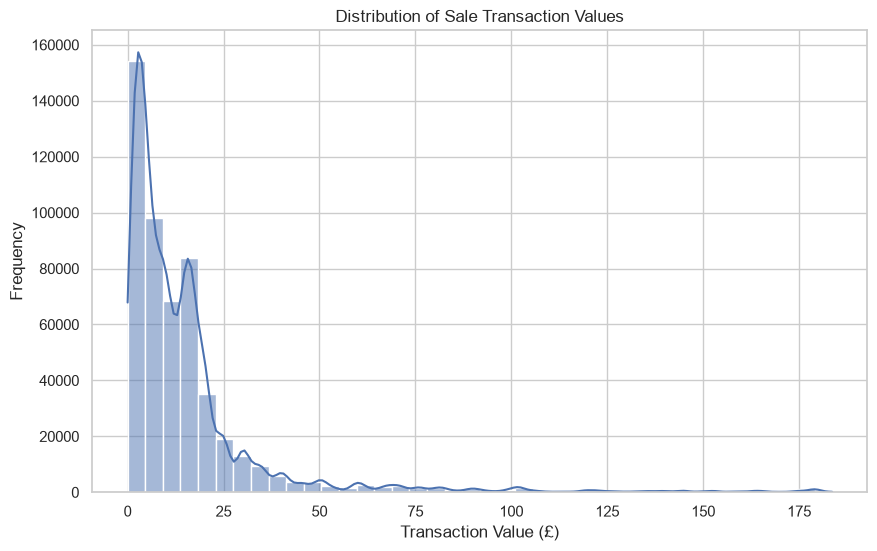

In [17]:
# Select transaction values from sale transactions
sale_values = df.loc[
    df['TransactionType'] == 'Sale',
    'TotalTransactionValue'
]

# Calculate the 99th percentile for visualisation purposes
upper_limit = sale_values.quantile(0.99)

# Plot the distribution of regular transaction values
plt.figure(figsize=(10, 6))

sns.histplot(
    sale_values[sale_values <= upper_limit],
    bins=40,
    kde=True
)

plt.title('Distribution of Sale Transaction Values')
plt.xlabel('Transaction Value (£)')
plt.ylabel('Frequency')
plt.show()


The distribution is strongly right-skewed, showing that most sale transactions are low in value, while fewer transactions have much higher values. Most transactions appear concentrated below approximately £25, with the frequency decreasing as transaction value increases. The top 1% of values were excluded from the visualisation only to improve readability.